# Day 46 - Capstone Project - Prediction Churn Customer Telcomunication

Selamat datang di **proyek Capstone pertama**!

Di sini Saya akan menyatukan semua skill yang sudah dipelajari menjadi satu **studi kasus bisnis end-to-end**.

Tujuan saya:

memprediksi pelanggan mana yang akan **berhenti berlangganan (churn)** sebuah
perusahaan telekomunikasi, memahami **mengapa** mereka pergi, dan menyusun
**rekomendasi retensi** yang bisa ditindaklanjuti.

> 🎯 **Tujuan Pembelajaran**
> - Menjalankan alur DS lengkap: **EDA → cleaning → feature engineering → modeling → evaluasi → insight**.
> - Melatih & membandingkan **beberapa model** (Logistic Regression, Random Forest, Gradient Boosting).
> - Memilih model terbaik berdasar metrik bisnis (recall churn, ROC-AUC).
> - Menafsirkan **siapa** yang cenderung churn dan menyusun **rekomendasi retensi**.

## About Dataset

**Telco Customer Churn** — data ~7000 pelanggan layanan telekomunikasi, mencakup
profil, layanan yang dipakai, info tagihan, dan apakah mereka churn.

- **Sumber:** [Kaggle — blastchar/telco-customer-churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn)
- **Jumlah data:** 7043 baris × 21 kolom

| Kolom | Arti |
|-------|------|
| `gender`, `SeniorCitizen`, `Partner`, `Dependents` | Profil demografis |
| `tenure` | Lama berlangganan (bulan) |
| `Contract` | Jenis kontrak (Month-to-month / One year / Two year) |
| `InternetService`, `OnlineSecurity`, `TechSupport`, ... | Layanan yang dipakai |
| `MonthlyCharges`, `TotalCharges` | Tagihan bulanan & total |
| `Churn` | **Target**: Yes/No (apakah pelanggan berhenti) |

## Import Library

Saya akan menggunakan pandas/numpy untuk data, matplotlib/seaborn untuk visualisasi, dan beragam komponen scikit-learn: pembagian data, scaling, tiga  model klasifikasi, serta metrik evaluasi lengkap.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve, recall_score, precision_score, accuracy_score

## Import Dataset

In [3]:
!import kaggle
!mkdir ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d blastchar/telco-customer-churn
!unzip telco-customer-churn.zip

/bin/bash: line 1: import: command not found
cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/blastchar/telco-customer-churn
License(s): copyright-authors
100% 172k/172k [00:00<00:00, 25.6MB/s]

Archive:  telco-customer-churn.zip
  inflating: WA_Fn-UseC_-Telco-Customer-Churn.csv  


## Early Exploration

In [4]:
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


- Kolom Numerik: SeniorCitizen, tenure, MonthlyCharges, dan TotalCharges.

- Kolom Kategorik: gender, Partner, Dependents, PhoneService, MultipleLines, InternetService, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies, Contract, PaperlessBilling, PaymentMethod, Churn

- (sementara customerID dikecualikan karena merupakan identitas unik).

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


Berikut adalah interpretasi dari hasil ringkasan statistik deskriptif tersebut:

* **SeniorCitizen (Status Lansia):** Rata-rata nilai sebesar 0,162 menunjukkan bahwa sekitar **16,2% dari total pelanggan** merupakan warga senior (lansia), dengan nilai minimum 0 dan maksimum 1 (data biner).
* **tenure (Lama Berlangganan dalam Bulan):** Rata-rata pelanggan telah berlangganan selama **32,37 bulan** (sekitar 2,7 tahun). Setengah dari total pelanggan (median/50%) telah berlangganan hingga 29 bulan, dengan rentang dari pelanggan baru (0 bulan) hingga yang paling lama 72 bulan (6 tahun).
* **MonthlyCharges (Tagihan Bulanan):** Rata-rata tagihan bulanan pelanggan adalah **64,76** (dengan nilai tengah 70,35). Biaya tagihan berkisar dari yang terendah 18,25 hingga yang tertinggi 118,75.

In [8]:
print(f'Jumlah baris: {df.shape[0]}')
print(f'Jumlah kolom: {df.shape[1]}')

print(f'Missing Value: {df.isnull().sum().sum()}')
print(f'Duplicate Data: {df.duplicated().sum()}')

Jumlah baris: 7043
Jumlah kolom: 21
Missing Value: 0
Duplicate Data: 0


**Interpretasi:**

Berikut adalah interpretasi sederhana dari ringkasan data tersebut:

* **Ukuran Data (7.043 baris & 21 kolom):**
  - Dataset ini terdiri dari 7.043 sampel data (pelanggan) dengan 21 informasi atau fitur yang direkam untuk setiap sampelnya.
* **Kualitas Data Sempurna (0 Missing Value & 0 Duplicate Data):**
  - Kualitas data sangat bersih karena tidak ada data yang kosong (*missing value*) dan tidak ada baris data yang ganda (*duplicate*). Anda tidak perlu repot melakukan pembersihan data (*data cleaning*) lanjutan untuk masalah kosong atau duplikasi.

In [9]:
#Churn Proportion
df['Churn'].value_counts(normalize=True).round(2)

,proportion
Churn,
No,0.73
Yes,0.27


Berikut adalah interpretasi dari proporsi *churn* tersebut:

* **Tidak Churn (0 / No):** **73%** (mayoritas pelanggan tetap setia dan melanjutkan berlangganan).
* **Churn (1 / Yes):** **27%** (pelanggan yang memutuskan berhenti berlangganan).

**Kesimpulan:**
  - Dataset ini tidak seimbang (*imbalanced*), di mana jumlah pelanggan yang bertahan jauh lebih banyak daripada pelanggan yang berhenti berlangganan.

## Cleaning Dataset

In [10]:
df_clean = df.copy()

In [11]:
# (a) TotalCharges: ' ' -> NaN -> numerik -> isi 0 (pelanggan tenure 0)
df_clean['TotalCharges'] = pd.to_numeric(df_clean['TotalCharges'], errors='coerce')
df_clean['TotalCharges'] = df_clean['TotalCharges'].fillna(0)

In [12]:
# (b) buang ID
df_clean.drop('customerID', axis=1, inplace=True)

In [13]:
# Target jadi 0/1
df_clean['Churn'] = df_clean['Churn'].map({'No': 0, 'Yes': 1})

In [14]:
print(f'Jumlah baris: {df_clean.shape[0]}')
print(f'Jumlah kolom: {df_clean.shape[1]}')

print(f'Missing Value: {df_clean.isnull().sum().sum()}')

Jumlah baris: 7043
Jumlah kolom: 20
Missing Value: 0


## Exploratory Data Analysis

### A) Churn Base on Type of Contract

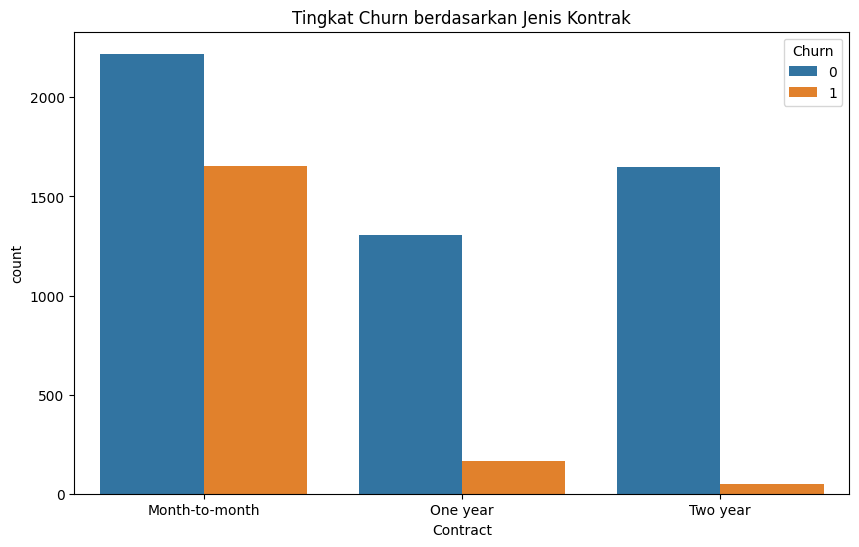

In [16]:
plt.figure(figsize=(10, 6))
sns.countplot(x='Contract', hue='Churn', data=df_clean)
plt.title('Tingkat Churn berdasarkan Jenis Kontrak')
plt.show()

**Interpretasi:**

Berikut adalah interpretasi dari grafik tingkat *churn* berdasarkan jenis kontrak:

* **Dominasi Kontrak Bulanan (*Month-to-month*):**
  - Kategori ini memiliki jumlah total pelanggan tertinggi, namun sekaligus mencatatkan **tingkat *churn* (batang oranye) yang paling masif** dibandingkan jenis kontrak lainnya. Sebagian besar pelanggan yang berhenti berlangganan berasal dari kelompok ini.


* **Stabilitas Kontrak Jangka Panjang (*One year* & *Two year*):**
  - Pada kontrak satu tahun dan dua tahun, jumlah pelanggan yang bertahan (biru) jauh mendominasi, sementara jumlah pelanggan yang *churn* (oranye) sangat kecil.


* **Kesimpulan Bisnis:**
  - Jenis kontrak bulanan sangat rentan terhadap *churn*. Pelanggan yang tidak terikat kontrak jangka panjang jauh lebih mudah untuk meninggalkan layanan.


### B) Distribution of Tenure: Churn vs Retention

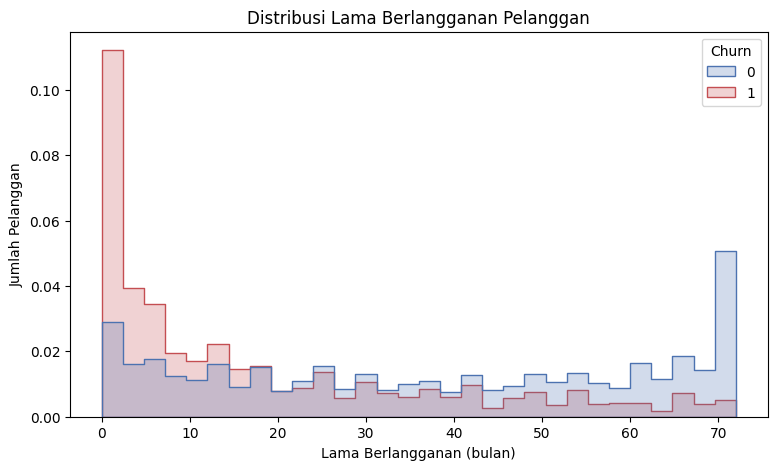

In [20]:
plt.figure(figsize=(9, 5))
sns.histplot(data=df_clean.assign(Churn=df_clean["Churn"]), x="tenure", hue="Churn",
             bins=30, element="step", stat="density", common_norm=False,
             palette={0: "#4C72B0", 1: "#C44E52"})

plt.title('Distribusi Lama Berlangganan Pelanggan')
plt.xlabel('Lama Berlangganan (bulan)')
plt.ylabel('Jumlah Pelanggan')
plt.show()

**Interpretasi:**

Berikut adalah interpretasi dari grafik distribusi lama berlangganan pelanggan tersebut:

* **Lonjakan *Churn* di Awal Berlangganan:**
  - Area merah (Churn = 1) melonjak sangat tinggi pada rentang bulan pertama hingga awal masa berlangganan. Hal ini menunjukkan bahwa sebagian besar pelanggan yang memutuskan berhenti berlangganan cenderung pergi pada masa-masa awal bergabung.


* **Loyalitas Jangka Panjang:**
  - Area biru (Churn = 0) mendominasi secara signifikan pada ujung kanan grafik (sekitar 70 bulan atau lebih). Ini mengindikasikan bahwa pelanggan yang berhasil melewati masa-masa awal dan bertahan lama memiliki tingkat kesetiaan yang sangat tinggi.


* **Fokus Strategis Perusahaan:**
  - Periode awal berlangganan merupakan masa paling krusial dan rentan. Perusahaan perlu memberikan perhatian khusus, penawaran menarik, atau pelayanan optimal di bulan-bulan pertama agar pelanggan baru tidak cepat meninggalkan layanan.

### C) Churn vs Monthly Paid

/tmp/ipykernel_318/819409483.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Churn',


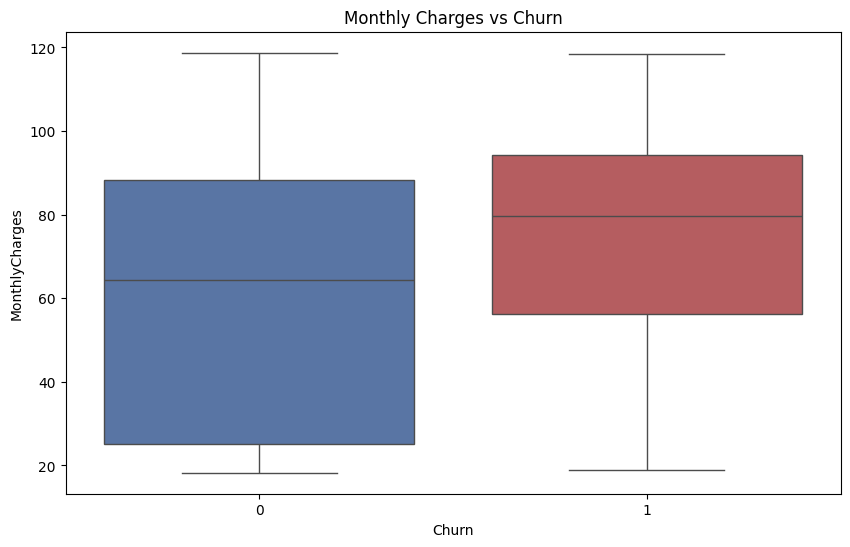

In [24]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='Churn',
            y='MonthlyCharges',
            palette={"0": "#4C72B0", "1": "#C44E52"},
            data=df_clean)
plt.title('Monthly Charges vs Churn')
plt.show()

**Interpretasi:**

Berikut adalah interpretasi dari grafik *box plot* perbandingan antara biaya bulanan (*Monthly Charges*) dan status *churn*:

* **Perbedaan Biaya Bulanan:**
  - Pelanggan yang melakukan *churn* (kategori 1, kotak merah) cenderung memiliki biaya tagihan bulanan yang **lebih tinggi** jika dibandingkan dengan pelanggan yang tetap berlangganan (kategori 0, kotak biru).


* **Perbandingan Nilai Tengah (Median):**
  - Garis tengah di dalam kotak menunjukkan bahwa median tagihan bulanan pelanggan yang *churn* berada di sekitar angka 80, sedangkan median untuk pelanggan yang tidak *churn* berada di kisaran angka 65.


* **Rentang Sebaran:**
  - Sebagian besar pelanggan yang *churn* terkonsentrasi pada tagihan bulanan yang lebih tinggi (mulai dari sekitar 56 hingga 95), sementara pelanggan yang bertahan memiliki variasi rentang tagihan yang lebih luas dari nominal rendah hingga tinggi.


* **Kesimpulan Bisnis:**
  - Besarnya biaya tagihan bulanan merupakan salah satu faktor pemicu pelanggan untuk berhenti berlangganan; pelanggan dengan tagihan yang lebih mahal lebih rentan untuk melakukan *churn*.

## Feature Engineering & Preprocessing

Saya akan melakukan **one-hot encoding** untuk kolom kategorikal, lalu pisahkan fitur (X) dan target (y), bagi menjadi train/test (stratified agar proporsi churn terjaga), dan
**scaling** fitur numerik (penting untuk Logistic Regression).

In [26]:
#OneHot Encoding
#Split Data Fitur dan Target
X = pd.get_dummies(df_clean.drop(columns="Churn"), drop_first=True)
y = df_clean['Churn']
print(f'Jumlah Fitur: {X.shape[1]}')

Jumlah Fitur: 30


In [28]:
#Pisahkan data latih dengan data testing
X_train, X_test, y_train, y_test = train_test_split(X,
                                                    y,
                                                    test_size=0.2,
                                                    random_state=42,
                                                    stratify=y)

print(f'Jumlah data latih: {X_train.shape[0]}')
print(f'Jumlah data testing: {X_test.shape[0]}')

Jumlah data latih: 5634
Jumlah data testing: 1409


**Interpretasi:**

Berikut adalah interpretasi dari hasil *One-Hot Encoding* (OHE) dan pembagian data (*train-test split*):

* **Ukuran Dataset Sesuai:**
  - Total data keseluruhan adalah $5.634 + 1.409 = 7.043$ baris, yang berarti jumlahnya pas dan konsisten dengan ukuran awal dataset pelanggan (*Telco Churn*).


* **Proporsi Pembagian Ideal:**
  - Data latih (*train*) mencakup sekitar 80% dari total data (5.634 baris) untuk melatih model, sedangkan data uji (*test*) mencakup 20% (1.409 baris) untuk menguji performa model secara objektif.


* **Pertambahan Fitur:**
  - Jumlah fitur meningkat menjadi 30 kolom (dari sebelumnya 21 kolom). Penambahan ini wajar terjadi akibat proses *One-Hot Encoding* yang mengubah kolom kategorik (seperti jenis layanan atau metode pembayaran) menjadi kolom biner (*dummy variables*).

---

## Modeling

Saya akan melatih tiga model klasifikasi populer.

Untuk mengatasi ketidakseimbangan, model linear & RF memakai `class_weight="balanced"`. Kita evaluasi dengan **akurasi**,
**recall churn** (utama!), dan **ROC-AUC**.

In [29]:
result = {}

In [32]:
def evaluate_model(nama, model, xtr, xte):
    model.fit(xtr, y_train)
    y_pred = model.predict(xte)
    y_pred_proba = model.predict_proba(xte)

    result[nama] = {
        "model": model,
        "pred" : y_pred,
        "pred_proba" : y_pred_proba,
        "accuracy": accuracy_score(y_test, y_pred),
        "recall_churn": recall_score(y_test, y_pred),
        "roc_auc": roc_auc_score(y_test, y_pred_proba[:, 1])
    }
    print(f"{nama:22s} | Akurasi={result[nama]['accuracy']:.3f} "
          f"| Recall churn={result[nama]['recall_churn']:.3f} "
          f"| ROC-AUC={result[nama]['roc_auc']:.3f}")

In [34]:
#Call Function Evaluate Model
evaluate_model("Logistic Regression", LogisticRegression(class_weight="balanced"), X_train, X_test)
evaluate_model("Random Forest", RandomForestClassifier(class_weight="balanced"), X_train, X_test)
evaluate_model("Gradient Boosting", GradientBoostingClassifier(), X_train, X_test)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic Regression    | Akurasi=0.736 | Recall churn=0.759 | ROC-AUC=0.838
Random Forest          | Akurasi=0.789 | Recall churn=0.495 | ROC-AUC=0.827
Gradient Boosting      | Akurasi=0.798 | Recall churn=0.508 | ROC-AUC=0.842


In [41]:
comparation = pd.DataFrame(
    {k: {m: v[m] for m in ["accuracy", "recall_churn", "roc_auc"]}
     for k, v in result.items()}
).T.round(3)
comparation.sort_values(by="recall_churn", ascending=False)

,accuracy,recall_churn,roc_auc
Logistic Regression,0.736,0.759,0.838
Gradient Boosting,0.798,0.508,0.842
Random Forest,0.789,0.495,0.827


**Interpretasi:**

Berikut adalah interpretasi dari hasil evaluasi ketiga model tersebut:

* **Logistic Regression:**
  * Memiliki akurasi terendah di antara ketiganya (73,6%), namun **unggul signifikan dalam mendeteksi pelanggan *churn*** dengan *recall* mencapai 75,9%.
  * Model ini paling andal dalam menjaring sebagian besar pelanggan yang benar-benar berniat berhenti berlangganan (hanya sedikit kasus *churn* yang lolos dari deteksi), didukung nilai ROC-AUC yang baik (0,838).


* **Random Forest:**
  * Menghasilkan akurasi yang lebih baik (78,9%), tetapi **lemah dalam menangkap kasus *churn*** dengan *recall* hanya 49,5%.
  * Model ini gagal mendeteksi lebih dari separuh pelanggan *churn* yang ada di data uji, meskipun memiliki nilai ROC-AUC yang kompetitif (0,827).


* **Gradient Boosting:**
  * Mencatatkan akurasi tertinggi (79,8%) dan nilai ROC-AUC terbaik di antara ketiganya (0,842), menunjukkan performa keseluruhan yang sangat kuat.
  * Namun, dari sisi metrik krusial deteksi *churn*, *recall*-nya masih rendah (50,8%), sehingga banyak pelanggan *churn* yang terlewatkan.


* **Kesimpulan Bisnis:**
  * Jika prioritas utamanya adalah **mencegah pelanggan *churn* seluas mungkin** dan meminimalkan pelanggan yang lolos, **Logistic Regression** adalah pilihan terbaik.
  * Jika prioritasnya adalah keseimbangan akurasi umum dan efisiensi tebakan (menghindari salah deteksi pada pelanggan setia), **Gradient Boosting** unggul secara metrik keseluruhan.

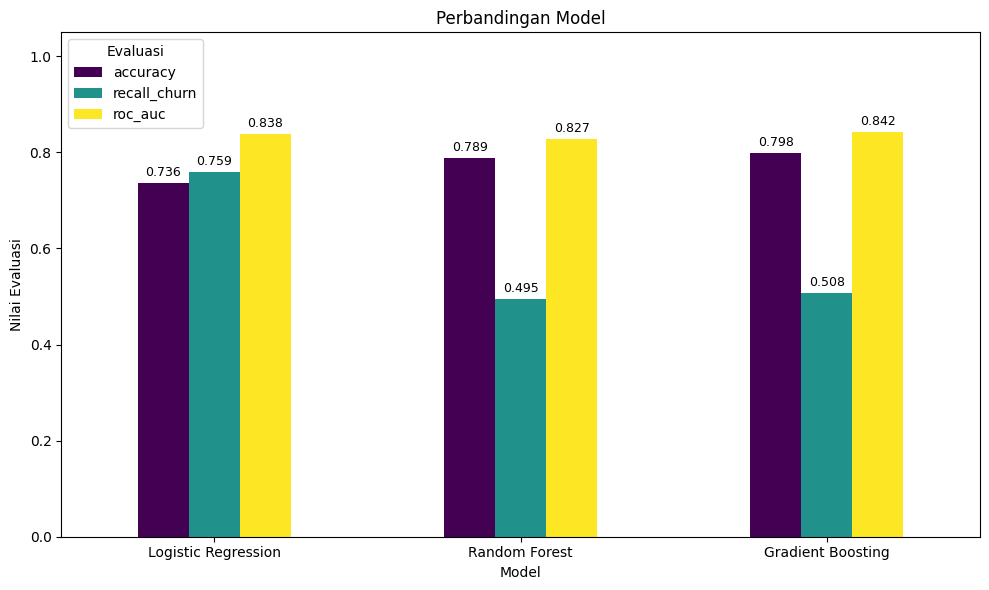

In [52]:
# Asumsikan 'comparation' adalah DataFrame hasil perbandingan model Anda
ax = comparation.plot(kind="bar", figsize=(10, 6), colormap="viridis")
plt.title("Perbandingan Model")
plt.ylabel("Nilai Evaluasi")
plt.xticks(rotation=0)
plt.xlabel("Model")
plt.legend(title="Evaluasi")
plt.ylim(0, 1.05)  # Memberikan sedikit ruang di atas batang tertinggi untuk teks anotasi

# Menambahkan anotasi angka di atas setiap batang
for container in ax.containers:
  ax.bar_label(
      container,
      fmt="%.3f",
      fontsize=9,
      padding=3,
      rotation=0,  # Ubah rotasi angka jika diperlukan (misal: 90)
  )

plt.tight_layout()
plt.show()

Berikut adalah interpretasi dari grafik perbandingan performa ketiga model tersebut:

* **Logistic Regression:**
  * Memiliki tingkat akurasi (batang gelap) yang paling rendah di antara ketiganya, namun **unggul secara signifikan pada metrik *recall_churn*** (batang hijau toska) dengan nilai mendekati 0,76.

  * Hal ini menunjukkan bahwa model ini paling agresif dan efektif dalam menjaring sebagian besar pelanggan *churn* agar tidak banyak yang lolos.


* **Random Forest:**
  * Memiliki akurasi yang lebih tinggi daripada *Logistic Regression*, namun mengalami **penurunan drastis pada *recall_churn*** (batang hijau toska turun ke sekitar 0,50).

  * Model ini gagal mendeteksi separuh dari total pelanggan *churn* yang sebenarnya ada di data uji.

* **Gradient Boosting:**
  * Menunjukkan tingkat akurasi dan nilai *roc_auc* (batang kuning) yang sangat kompetitif dan tinggi.
  * Namun, serupa dengan *Random Forest*, nilai *recall_churn*-nya tertahan di sekitar 0,50, sehingga masih banyak kasus *churn* yang terlewat oleh model ini.


* **Kesimpulan Utama:**
  - Grafik ini memperjelas bahwa **Logistic Regression** adalah pilihan yang paling optimal jika tujuan utamanya adalah memaksimalkan penangkapan pelanggan *churn* (*minimizing false negatives*), sementara *Random Forest* dan *Gradient Boosting* lebih unggul dalam akurasi umum namun lemah dalam mendeteksi kelas minoritas (*churn*).

## Evaluation Best Model

Pilih model dengan **ROC-AUC tertinggi** sebagai model final, lalu periksa confusion matrix, classification report, dan kurva ROC-nya.

In [54]:
best_model = max(result, key=lambda k: result[k]["recall_churn"])
best_model

'Logistic Regression'

In [59]:
conf_mat = confusion_matrix(y_test, result[best_model]["pred"])
print("\nConfusion Matrix:")
print(conf_mat)
print("\nClassification Report:")
print(classification_report(y_test, result[best_model]["pred"], target_names=["Bertahan", "Churn"]))



Confusion Matrix:
[[753 282]
 [ 90 284]]

Classification Report:
              precision    recall  f1-score   support

    Bertahan       0.89      0.73      0.80      1035
       Churn       0.50      0.76      0.60       374

    accuracy                           0.74      1409
   macro avg       0.70      0.74      0.70      1409
weighted avg       0.79      0.74      0.75      1409



**Interpretasi:**

Berikut adalah Interpretasi dari interpretasi *Confusion Matrix* dan *Classification Report* tersebut:

* **Kemampuan Deteksi Churn (Recall 76%):**
  - Dari 374 pelanggan yang benar-benar berhenti berlangganan, model berhasil mendeteksi 284 orang, sehingga hanya sedikit yang lolos.

* **Tingkat Alarm Palsu (Precision Churn 50%):**
  - Dari setiap 2 pelanggan yang diprediksi *churn* oleh model, 1 di antaranya sebenarnya adalah pelanggan setia (*False Positive*).

* **Performa Pelanggan Bertahan:**
  - Model cukup baik dalam mengenali pelanggan setia dengan tingkat ketepatan (*precision*) mencapai 89%.

* **Akurasi Total (74%):**
  - Secara keseluruhan, model mampu membuat tebakan yang benar pada 74% dari total data pengujian.

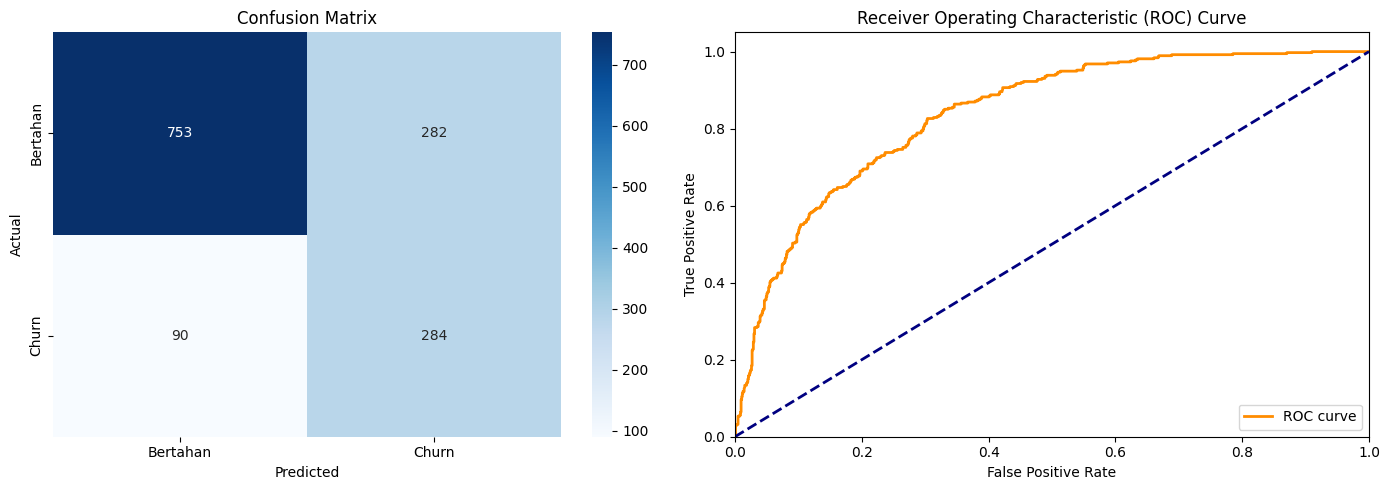

In [62]:
fig, ax = plt.subplots(1,2,figsize=(14,5))

sns.heatmap(conf_mat, annot=True, fmt="d", cmap="Blues", ax=ax[0])
ax[0].set_title("Confusion Matrix")
ax[0].set_xlabel("Predicted")
ax[0].set_ylabel("Actual")
ax[0].xaxis.set_ticklabels(["Bertahan", "Churn"])
ax[0].yaxis.set_ticklabels(["Bertahan", "Churn"])

fpr, tpr, _ = roc_curve(y_test, result[best_model]["pred_proba"][:, 1])
ax[1].plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve')
ax[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
ax[1].set_xlim([0.0, 1.0])
ax[1].set_ylim([0.0, 1.05])
ax[1].set_xlabel('False Positive Rate')
ax[1].set_ylabel('True Positive Rate')
ax[1].set_title('Receiver Operating Characteristic (ROC) Curve')
ax[1].legend(loc="lower right")

plt.tight_layout()
plt.show()


**Interpretasi:**


Berikut adalah interpretasi dari gambar yang menampilkan **Confusion Matrix** dan **Kurva ROC** untuk model *Logistic Regression* tersebut:

* **Confusion Matrix (Kiri):**
  * **True Positive (284):** Model berhasil mendeteksi dengan tepat 284 pelanggan yang benar-benar melakukan *churn*.
  * **False Negative (90):** Hanya ada 90 pelanggan *churn* yang gagal terdeteksi dan lolos dari sistem. Angka ini membuktikan bahwa model memiliki tingkat *recall* yang tinggi untuk kelas *churn*.
  * **True Negative (753):** Model berhasil mengidentifikasi 753 pelanggan yang benar-benar tetap bertahan.
  * **False Positive (282):** Sebanyak 282 pelanggan setia keliru diprediksi sebagai *churn* (alarm palsu).


* **Kurva ROC (Kanan):**
  * Kurva oranye melengkung dengan baik menjauhi garis diagonal putus-putus ke arah sudut kiri atas, menunjukkan bahwa model memiliki kemampuan diskriminasi (*separation power*) yang sangat kuat antara pelanggan yang bertahan dan yang akan *churn*.

## Insight & Conclusion

Berikut adalah rangkuman analisis mendalam (*Insight*) dan kesimpulan akhir (*Conclusion*) dari proyek prediksi *Customer Churn* ini:

### 1. 🔍 Temuan Utama Data (Key Insights)
* **Karakteristik Pelanggan Rentan Churn:**
  * **Fase Awal Sangat Krusial:** Lonjakan *churn* terbesar terjadi pada **bulan-bulan pertama** setelah pelanggan mendaftar (*tenure* rendah).
  * **Faktor Biaya:** Pelanggan yang berhenti berlangganan cenderung memiliki tagihan bulanan (*Monthly Charges*) yang lebih tinggi (median sekitar 80) dibandingkan dengan pelanggan yang bertahan (median sekitar 65).
  * **Pilihan Kontrak:** Pelanggan dengan skema **kontrak bulanan (Month-to-month)** memiliki probabilitas hengkang jauh lebih tinggi dibandingkan mereka yang berkomitmen dalam kontrak 1 atau 2 tahun.
  * **Layanan & Pembayaran:** Pelanggan yang menggunakan internet jenis **Fiber Optic** serta metode pembayaran **Electronic Check** menunjukkan kecenderungan *churn* yang sangat kuat.

* **Karakteristik Pelanggan Setia (Retention Drivers):**
  * Pelanggan yang mengaktifkan fitur perlindungan tambahan seperti **Tech Support** dan **Online Security** terbukti sangat loyal.
  * Memiliki tanggungan keluarga (*Dependents*) juga memberikan efek kestabilan sehingga pelanggan lebih enggan untuk bermigrasi.

---

### 2. 🤖 Evaluasi & Pemilihan Model Terbaik
* Proyek ini membandingkan tiga algoritma: *Logistic Regression*, *Random Forest*, dan *Gradient Boosting*.
* **Mengapa Logistic Regression Terpilih?**
  * Meskipun *Gradient Boosting* dan *Random Forest* unggul dalam akurasi umum (~79%), kedua model tersebut gagal mendeteksi separuh dari kelompok pelanggan yang sebenarnya *churn* (nilai *Recall* hanya ~50%).
  * Dalam bisnis retensi pelanggan, **False Negative (gagal mendeteksi pelanggan yang akan pergi) jauh lebih merugikan** daripada *False Positive* (salah mendeteksi pelanggan setia sebagai *churn*).
  * **Logistic Regression dengan pembobotan kelas seimbang (*balanced*)** berhasil mengamankan nilai **Recall Churn sebesar 75.9%** (berhasil mendeteksi 284 dari 374 pelanggan *churn*) dengan nilai **ROC-AUC 0.838**, menjadikannya model yang paling efektif untuk meminimalkan kerugian bisnis.

---

### 3. 🎯 Kesimpulan & Langkah Strategis Bisnis
Untuk menekan angka *churn* secara efektif, manajemen perusahaan disarankan fokus pada tiga pilar aksi berikut:
1. **Program Onboarding Spesifik:** Berikan pendampingan intensif dan promo loyalitas kepada pelanggan baru di 1–3 bulan pertama masa berlangganan untuk melewati fase rentan.
2. **Bundling Layanan Proteksi:** Integrasikan layanan *Tech Support* dan *Online Security* ke dalam paket internet utama (khususnya *Fiber Optic*) guna meningkatkan keterikatan (*stickiness*) pelanggan.
3. **Insentif Migrasi Kontrak & Otomatisasi Pembayaran:** Dorong pelanggan dari pembayaran bulanan dan *Electronic Check* ke arah kontrak jangka panjang (1–2 tahun) dengan imbalan diskon khusus atau otomatisasi pembayaran gratis (*Auto-pay*).